# Análisis de métricas: eje B (emocionalidad gramatical)

**Proyecto 1:** análisis morfosintáctico de reseñas de cine y series en español con POS Tagging.

En este notebook se compara la estructura gramatical de las reseñas según su valoración, usando el etiquetado de `data/results/pos_analysis.csv.gz`.

**Preguntas del eje B que se responden aquí**

1. ¿Las reseñas con calificación baja usan más negaciones (no, nunca, jamás, nada, ni) que las de calificación alta?
2. ¿Las reseñas negativas usan más adverbios de intensidad ("muy", "demasiado", "totalmente")?

**Cómo se calculan las métricas**

- Se excluye la puntuación (`PUNCT`) y toda frecuencia se normaliza por cada 100 tokens.
- Las funciones están en `src/metrics.py`: `indice_negacion` e `indice_intensidad`.
- Negaciones: no, nunca, jamás, nada, ni.
- Adverbios de intensidad (etiquetados como `ADV`): muy, demasiado, totalmente, tan, bastante, sumamente, absolutamente, completamente, extremadamente, realmente.
- Valoración: negativa (calificación 1 a 4), intermedia (5 a 6) y positiva (7 a 10).

## 1. Carga de datos

In [4]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src.metrics import indice_negacion, indice_intensidad

tokens = pd.read_csv("../data/results/pos_analysis.csv.gz", keep_default_na=False)
df = pd.read_csv("../data/processed/resenas_limpias.csv")

palabras = tokens[tokens["upos_spacy"] != "PUNCT"]
por_resena = palabras.groupby("id").size().rename("n_tokens").reset_index()

print(tokens.shape, df.shape)
print(por_resena.shape)
print(por_resena["n_tokens"].describe())

(1361253, 7) (6283, 11)
(6283, 2)
count    6283.000000
mean      191.414452
std        88.246293
min        29.000000
25%       128.000000
50%       171.000000
75%       245.000000
max       471.000000
Name: n_tokens, dtype: float64


## 2. Cálculo de las métricas por reseña

In [5]:
metricas = (por_resena
            .merge(indice_negacion(tokens), on="id")
            .merge(indice_intensidad(tokens), on="id")
            .merge(df[["id", "valoracion", "calificacion", "genero", "periodo"]], on="id"))

orden = ["negativa", "intermedia", "positiva"]
print(metricas.shape)
print(metricas.head())

(6283, 8)
   id  n_tokens   neg_100   int_100  valoracion  calificacion     genero  \
0   1       109  0.917431  0.917431    positiva            10  Animation   
1   2       123  1.626016  0.813008  intermedia             6     Comedy   
2   3       342  1.169591  1.169591    positiva             7      Drama   
3   4       180  0.555556  3.333333    positiva             9     Horror   
4   5       387  1.808786  0.775194    positiva             7     Action   

            periodo  
0        antes_2010  
1  2010_en_adelante  
2  2010_en_adelante  
3  2010_en_adelante  
4  2010_en_adelante  


## 3. Pregunta 1: negaciones

¿Las reseñas con calificación baja usan más negaciones que las de calificación alta?

In [6]:
print(metricas.groupby("valoracion")["neg_100"].agg(["count", "mean", "median"]).reindex(orden))
print(metricas.groupby("calificacion")["neg_100"].mean())

            count      mean    median
valoracion                           
negativa     1203  2.281398  2.066116
intermedia    905  1.842150  1.639344
positiva     4175  1.488126  1.315789
calificacion
1     2.397700
2     2.175807
3     2.323356
4     2.118266
5     1.993687
6     1.733951
7     1.573216
8     1.415903
9     1.415289
10    1.527625
Name: neg_100, dtype: float64


Las reseñas que tienen calificaciones más bajas usan más negaciones, un promedio de 2,28 negaciones por cada 100 palabras, que las que tienen calificaciones altas que tienen un promedio de 1,49. También si se observa cada calificación por separados, el índice va bajando casi de forma continua, de 2.40 en las reseñas de una estrella a 1.42 en las de 8 u 9 estrellas.

## 4. Pregunta 2: adverbios de intensidad

¿Las reseñas negativas usan más adverbios de intensidad?

In [7]:
print(metricas.groupby("valoracion")["int_100"].agg(["count", "mean", "median"]).reindex(orden))
print(metricas.groupby("calificacion")["int_100"].agg(["count", "mean"]))

            count      mean    median
valoracion                           
negativa     1203  1.163324  0.973236
intermedia    905  1.214195  1.052632
positiva     4175  1.146479  0.909091
              count      mean
calificacion                 
1               478  1.053840
2               241  1.236790
3               238  1.221367
4               246  1.247932
5               377  1.259241
6               528  1.182031
7               815  1.192384
8               963  1.174481
9               841  1.169257
10             1556  1.092793


En estos datos se puede observar que no hay mucha diferencia entre las reseñas negativas y positivas a la hora de usar adverbios de intensidad. Las calificaciones por separado tienen los valores entre 1.05 y 1.26 y tampoco siguen una tendencia ordenada, hay reseñas con calificaciones más altas que tienen un uso mayor de adverbios que otras calificaciones.

## 5. Gráfico comparativo y guardado de resultados

Las dos métricas por calificación, con la misma escala vertical (de 0 a 3) para que se puedan comparar a simple vista. La figura se guarda en `outputs/figures/` y las métricas por reseña en `data/results/metricas_eje_b.csv`.

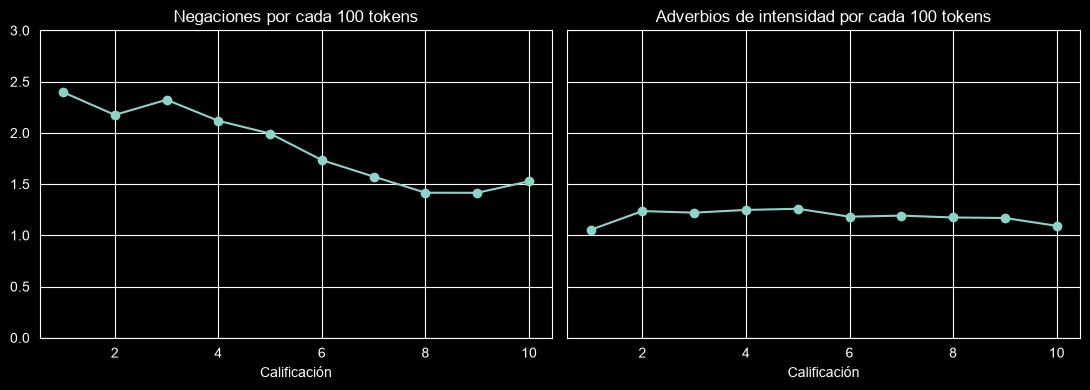

In [8]:
por_nota = metricas.groupby("calificacion")[["neg_100", "int_100"]].mean()

fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
por_nota["neg_100"].plot(ax=ejes[0], marker="o")
ejes[0].set_title("Negaciones por cada 100 tokens")
por_nota["int_100"].plot(ax=ejes[1], marker="o")
ejes[1].set_title("Adverbios de intensidad por cada 100 tokens")
ejes[0].set_ylim(0, 3)
for eje in ejes:
    eje.set_xlabel("Calificación")
plt.tight_layout()
plt.savefig("../outputs/figures/eje_b_negaciones_intensidad.png", dpi=150, bbox_inches="tight")
plt.show()

metricas.to_csv("../data/results/metricas_eje_b.csv", index=False)